# Neural v2 on EVA Transcription
## Can the favorable |Σ|/|A| ratio break the decipherment ceiling?

The STA1 2.0 transcription uses 166 glyph types for 27 Hebrew characters (|Σ|/|A| = 6.1),
placing the problem in an **unsolvable** regime for monoalphabetic substitution.

The EVA transcription collapses allographic variants into ~34 types (|Σ|/|A| = 1.26),
comparable to the Zodiac 340 cipher (1.32) which **was** solved.

This notebook runs the full Neural v2 pipeline on EVA to test whether:
1. The more favorable ratio enables higher n-gram realism
2. Root matching improves beyond the 3-root ceiling
3. The structural limit is inherent to the manuscript, not the transcription

### Key simplifications for EVA
- **No C/V role constraints**: EVA tokens don't carry syllabic position inshapetion
- **No grammar anchors**: Position-based anchors require STA1's fine-grained glyph classes
- **Unconstrained mapping**: All 34 EVA types can map to any of 27 Hebrew characters

In [1]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, json, warnings, time, copy
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.spatial.distance import jensenshannon

warnings.filterwarnings('ignore')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
print('Ready.')

Device: cuda
Ready.


In [2]:
# ── Cell 2: Parse EVA corpus ─────────────────────────────────────────
# Reused from 23_transcription_robustness.ipynb

EVA_MULTI = ['ckh', 'cth', 'cfh', 'cph', 'ch', 'sh', 'ii', 'ee']

def tokenize_eva_word(raw):
    """Tokenize an EVA word string into a list of EVA glyphs."""
    raw = re.sub(r'[\[\]?!*%]', '', raw)
    raw = re.sub(r'@\d+;', '@', raw)
    if not raw:
        return []
    glyphs = []
    i = 0
    while i < len(raw):
        matched = False
        for multi in EVA_MULTI:
            if raw[i:i+len(multi)] == multi:
                glyphs.append(multi)
                i += len(multi)
                matched = True
                break
        if not matched:
            c = raw[i]
            if c.isalpha() and c.lower() != 'w':
                glyphs.append(c.lower())
            elif c == '@':
                glyphs.append('@')
            i += 1
    return glyphs


def parse_eva_ivtff(text):
    """Parse EVA IVTFF text → words list and folio_words dict."""
    words = []
    folio_words = defaultdict(list)
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        if re.match(r'^<[^>]+>\s*<!', line):
            continue
        match = re.match(r'^<([^.>]+)[^>]*>\s+(.*)', line)
        if not match:
            continue
        folio = match.group(1)
        text_part = match.group(2).strip()
        text_part = re.sub(r'\{[^}]*\}', '', text_part)
        text_part = re.sub(r'<[^>]*>', '', text_part)
        text_part = text_part.replace('-', '.').replace(',', '.')
        for w_raw in text_part.split('.'):
            w_raw = w_raw.strip()
            if not w_raw:
                continue
            glyphs = tokenize_eva_word(w_raw)
            if glyphs:
                words.append(glyphs)
                folio_words[folio].append(glyphs)
    return words, folio_words


# Load EVA
eva_cache = Path('corpus/voynich_eva.txt')
if eva_cache.exists():
    eva_text = eva_cache.read_text(encoding='utf-8')
    print(f'Loaded cached EVA: {eva_cache}')
else:
    EVA_URLS = [
        'https://www.voynich.nu/data/ZL3b-n.txt',
        'https://www.voynich.nu/data/IT2a-n.txt',
        'https://www.voynich.nu/data/VT0e-n.txt',
    ]
    for url in EVA_URLS:
        try:
            print(f'Trying {url}...')
            resp = requests.get(url, timeout=30,
                                headers={'User-Agent': 'VoynichResearch/1.0'})
            resp.raise_for_status()
            eva_text = resp.text
            eva_cache.write_text(eva_text, encoding='utf-8')
            print(f'Downloaded: {url.split("/")[-1]}')
            break
        except Exception as e:
            print(f'  Failed: {e}')

palabras, folio_words = parse_eva_ivtff(eva_text)
VOCAB = sorted({g for w in palabras for g in w})
N_VOYNICH = len(palabras)

print(f'\nEVA corpus: {N_VOYNICH:,} words, '
      f'{sum(len(w) for w in words):,} glyphs, '
      f'{len(VOCAB)} types')
print(f'Vocabulary: {" ".join(VOCAB)}')
print(f'Mean word length: {np.mean([len(w) for w in words]):.2f}')

Loaded cached EVA: corpus/voynich_eva.txt

EVA corpus: 34,725 words, 149,496 glyphs, 34 types
Vocabulary: @ a b c cfh ch ckh cph cth d e ee f g h i ii j k l m n o p q r s sh t u v x y z
Mean word length: 4.31


In [3]:
# ── Cell 3: Download Hebrew corpus + train LSTM ────────────────────────

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Hebrew corpus (Torah)...')
hebrew_words_full = descargar_hebreo()

# Subsample to match Voynich size
rng_sub = np.random.default_rng(42)
if len(hebrew_words_full) > N_VOYNICH:
    idx = rng_sub.choice(len(hebrew_words_full), size=N_VOYNICH, replace=False)
    hebrew_words = [hebrew_words_full[i] for i in sorted(idx)]
else:
    hebrew_words = hebrew_words_full
print(f'Hebrew subsampled: {len(hebrew_words):,} words')

target_chars = sorted(set(c for w in hebrew_words for c in w))
print(f'Hebrew chars: {len(target_chars)}')
print(f'|Σ|/|A| = {len(VOCAB)}/{len(target_chars)} = {len(VOCAB)/len(target_chars):.2f}')

Descargando corpus hebreo (Torah)...
  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 palabras
Hebreo subsampleado: 34,725 palabras
Hebrew chars: 27
|Σ|/|A| = 34/27 = 1.26


Neural LM vocab: 31 tokens (27 chars + 4 special)
Train: 27,780, Val: 6,945

Training Neural LM (30 epochs, patience=5)...
  Epoch  1: train=2.3639, val=2.1619
  Epoch  5: train=2.0603, val=2.0407
  Epoch 10: train=2.0326, val=2.0258
  Epoch 15: train=2.0186, val=2.0196
  Epoch 20: train=2.0083, val=2.0152
  Epoch 25: train=2.0022, val=2.0133
  Epoch 30: train=1.9976, val=2.0132
  Early stopping at epoch 30

Training done in 45.3s, best val_loss=2.0133


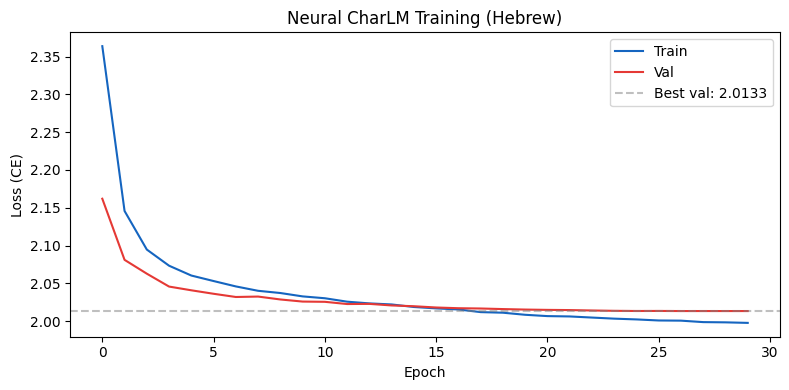

In [4]:
# ── Cell 4: NeuralCharLM — LSTM architecture ──────────────────────────

class CharDataset(Dataset):
    def __init__(self, words, char2idx):
        self.samples = []
        bos = char2idx['<w>']
        eos = char2idx['</w>']
        for word in words:
            indices = [bos, bos] + [char2idx.get(c, char2idx.get('<unk>', 0)) for c in word] + [eos]
            for i in range(2, len(indices)):
                ctx = indices[i-2:i]
                target = indices[i]
                self.samples.append((ctx, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ctx, target = self.samples[idx]
        return torch.tensor(ctx, dtype=torch.long), torch.tensor(target, dtype=torch.long)


class NeuralCharLM(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=192, n_layers=2, dropout=0.2):
        super().__init__()
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers,
                           dropout=dropout if n_layers > 1 else 0.0,
                           batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)
        self.char2idx = None
        self.idx2char = None

    def forward(self, x, hidden=None):
        emb = self.dropout(self.embedding(x))
        out, hidden = self.lstm(emb, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden

    def log_prob(self, word, temperature=1.0):
        self.eval()
        with torch.no_grad():
            bos = self.char2idx['<w>']
            eos = self.char2idx['</w>']
            unk = self.char2idx.get('<unk>', 0)
            indices = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
            total_lp = 0.0
            for i in range(2, len(indices)):
                ctx = torch.tensor([[indices[i-2], indices[i-1]]], device=DEVICE)
                logits, _ = self.forward(ctx)
                logits_t = logits[0, -1, :] / temperature
                log_probs = torch.log_softmax(logits_t, dim=0)
                total_lp += log_probs[indices[i]].item() / math.log(2)
            return total_lp

    def batch_log_prob(self, words, temperature=1.0):
        self.eval()
        bos = self.char2idx['<w>']
        eos = self.char2idx['</w>']
        unk = self.char2idx.get('<unk>', 0)
        with torch.no_grad():
            all_ctx = []
            all_tgt = []
            word_boundaries = [0]
            for word in words:
                seq = [bos, bos] + [self.char2idx.get(c, unk) for c in word] + [eos]
                for i in range(2, len(seq)):
                    all_ctx.append([seq[i-2], seq[i-1]])
                    all_tgt.append(seq[i])
                word_boundaries.append(len(all_ctx))
            n_total = len(all_ctx)
            if n_total == 0:
                return np.zeros(len(words))
            ctx_t = torch.tensor(all_ctx, device=DEVICE)
            tgt_t = torch.tensor(all_tgt, device=DEVICE)
            CHUNK = 16384
            all_lps = []
            for start in range(0, n_total, CHUNK):
                end = min(start + CHUNK, n_total)
                logits, _ = self.forward(ctx_t[start:end])
                logits_last = logits[:, -1, :] / temperature
                log_p = torch.log_softmax(logits_last, dim=-1)
                target_lp = log_p.gather(1, tgt_t[start:end].unsqueeze(1)).squeeze(1)
                all_lps.append(target_lp)
            all_lps = torch.cat(all_lps).cpu().numpy() / math.log(2)
            word_lps = np.zeros(len(words))
            for wi in range(len(words)):
                start = word_boundaries[wi]
                end = word_boundaries[wi + 1]
                if start < end:
                    word_lps[wi] = all_lps[start:end].sum()
            return word_lps

    def perplexity(self, words, temperature=1.0):
        self.eval()
        word_lps = self.batch_log_prob(words, temperature)
        total_lp = word_lps.sum()
        total_n = sum(len(w) + 1 for w in words)
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# Build vocab and indices
all_chars_heb = sorted(set(c for w in hebrew_words for c in w))
special_tokens = ['<pad>', '<w>', '</w>', '<unk>']
char_vocab = special_tokens + all_chars_heb
char2idx = {c: i for i, c in enumerate(char_vocab)}
idx2char = {i: c for c, i in char2idx.items()}

print(f'Neural LM vocab: {len(char_vocab)} tokens ({len(all_chars_heb)} chars + {len(special_tokens)} special)')

# ── Train ──
rng_split = np.random.default_rng(42)
n_val = int(0.2 * len(hebrew_words))
perm = rng_split.permutation(len(hebrew_words))
val_idx = set(perm[:n_val])
train_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i not in val_idx]
val_words = [hebrew_words[i] for i in range(len(hebrew_words)) if i in val_idx]
print(f'Train: {len(train_words):,}, Val: {len(val_words):,}')

train_dataset = CharDataset(train_words, char2idx)
val_dataset = CharDataset(val_words, char2idx)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=0)

neural_lm = NeuralCharLM(len(char_vocab), embed_dim=32, hidden_dim=192,
                          n_layers=2, dropout=0.2).to(DEVICE)
neural_lm.char2idx = char2idx
neural_lm.idx2char = idx2char

optimizer = optim.AdamW(neural_lm.parameters(), lr=2e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
criterion = nn.CrossEntropyLoss(ignore_index=char2idx['<pad>'])

N_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses = [], []

print(f'\nTraining Neural LM ({N_EPOCHS} epochs, patience={PATIENCE})...')
t0 = time.time()

for epoch in range(N_EPOCHS):
    neural_lm.train()
    epoch_loss, n_batches = 0.0, 0
    for ctx_batch, target_batch in train_loader:
        ctx_batch = ctx_batch.to(DEVICE)
        target_batch = target_batch.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = neural_lm(ctx_batch)
        loss = criterion(logits[:, -1, :], target_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(neural_lm.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_loss = epoch_loss / max(n_batches, 1)
    train_losses.append(train_loss)

    neural_lm.eval()
    val_loss, n_val_batches = 0.0, 0
    with torch.no_grad():
        for ctx_batch, target_batch in val_loader:
            ctx_batch = ctx_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            logits, _ = neural_lm(ctx_batch)
            loss = criterion(logits[:, -1, :], target_batch)
            val_loss += loss.item()
            n_val_batches += 1
    val_loss = val_loss / max(n_val_batches, 1)
    val_losses.append(val_loss)
    scheduler.step()

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'  Epoch {epoch+1:2d}: train={train_loss:.4f}, val={val_loss:.4f}')

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0
        best_state_dict = copy.deepcopy(neural_lm.state_dict())
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'  Early stopping at epoch {epoch+1}')
            break

elapsed = time.time() - t0
print(f'\nTraining done in {elapsed:.1f}s, best val_loss={best_val_loss:.4f}')
neural_lm.load_state_dict(best_state_dict)

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(train_losses, label='Train', color='#1565C0')
ax.plot(val_losses, label='Val', color='#E53935')
ax.axhline(best_val_loss, ls='--', color='gray', alpha=0.5, label=f'Best val: {best_val_loss:.4f}')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss (CE)')
ax.set_title('Neural CharLM Training (Hebrew)')
ax.legend(); plt.tight_layout(); plt.show()

In [5]:
# ── Cell 5: Mapping state + Scoring (simplified for EVA) ──────────────
# No C/V role constraints, no grammar anchors — unconstrained mapping

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change_tracked(self, rng):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        new.mapping[glyph] = rng.choice(self.target_chars)
        return new, glyph

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words):
    """Frequency-based initialization: most frequent glyph → most frequent char."""
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    glyphs_sorted = sorted(vocab_glyphs, key=lambda g: gf[g], reverse=True)
    chars_sorted = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
    mapping = {}
    for i, g in enumerate(glyphs_sorted):
        mapping[g] = chars_sorted[i % len(chars_sorted)]
    return mapping


def build_glyph_word_index(words):
    idx = defaultdict(list)
    for wi, word in enumerate(words):
        for g in set(word):
            idx[g].append(wi)
    return idx


# ── Scoring functions (simplified: no positional, no grammar) ──

def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    return H / H_max if H_max > 1e-10 else 0.0


def score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature=1.0):
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    word_lps = neural_lm.batch_log_prob(mapped, temperature)
    return float(np.mean(word_lps)), word_lps


def score_cardinality(mapping_state, K_max=23):
    K = len(set(mapping_state.mapping.values()))
    if K >= K_max:
        return 0.0
    return -((K_max - K) ** 2)


def score_total_neural(mapping_state, words_sample, neural_lm, temperature,
                       w_lm=2.0, w_card=0.5, w_ent=0.3, K_max=23):
    s_lm, word_lps = score_neural_lm_batch(mapping_state, words_sample, neural_lm, temperature)
    s_card = score_cardinality(mapping_state, K_max)
    s_ent = score_entropy(mapping_state)
    total = w_lm * s_lm + w_card * s_card + w_ent * s_ent
    return total, word_lps


def score_total_incremental(proposal, changed_glyph, words_sample, neural_lm,
                            temperature, glyph_word_idx, prev_word_lps,
                            w_lm=2.0, w_card=0.5, w_ent=0.3, K_max=23):
    new_word_lps = prev_word_lps.copy()
    affected = glyph_word_idx.get(changed_glyph, [])
    if affected:
        affected_mapped = [proposal.apply_word(words_sample[wi]) for wi in affected]
        new_lps = neural_lm.batch_log_prob(affected_mapped, temperature)
        for j, wi in enumerate(affected):
            new_word_lps[wi] = new_lps[j]
    s_lm = float(np.mean(new_word_lps))
    s_card = score_cardinality(proposal, K_max)
    s_ent = score_entropy(proposal)
    total = w_lm * s_lm + w_card * s_card + w_ent * s_ent
    return total, new_word_lps


# ── Root counting helpers ──
HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')
HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}

def extract_skeleton_deterministic(mapped_word):
    skeleton = []
    for char in mapped_word:
        if char in HEBREW_MATRES:
            continue
        if char in HEBREW_CONSONANTS_SET:
            skeleton.append(char)
    return ''.join(skeleton)

def count_roots_quick(mapping, palabras_sample, top_n=200):
    word_freq = Counter(tuple(w) for w in palabras_sample)
    top_words = word_freq.most_common(top_n)
    roots_matched = set()
    n_matches = 0
    for word_tuple, freq in top_words:
        mapped = [mapping.get(g, '?') for g in word_tuple]
        skel = extract_skeleton_deterministic(mapped)
        if len(skel) < 3:
            continue
        for i in range(len(skel) - 2):
            trigram = skel[i:i+3]
            if trigram in HEBREW_ROOTS:
                roots_matched.add(trigram)
                n_matches += 1
    return roots_matched, n_matches


print(f'Scoring functions loaded (simplified for EVA: no C/V, no grammar)')
print(f'Hebrew roots: {len(HEBREW_ROOTS)}')

Scoring functions loaded (simplified for EVA: no C/V, no grammar)
Hebrew roots: 100


In [6]:
# ── Cell 6: Multi-Seed EM ─────────────────────────────────────────────

N_SEEDS = 20
T_FIXED = 3.0
SCORE_KW = dict(w_card=0.5, K_max=20)
SAMPLE_EM = 3000
EM_ITERS = 2000
EM_PATIENCE = 100
PROPOSALS_PER_ITER = 200

# Prepare EM sample
rng_sample = np.random.default_rng(42)
if len(palabras) > SAMPLE_EM:
    idx_em = rng_sample.choice(len(palabras), size=SAMPLE_EM, replace=False)
    words_em = [palabras[i] for i in idx_em]
else:
    words_em = palabras

glyph_word_idx_em = build_glyph_word_index(words_em)

# Base frequency mapping
base_mapping = init_frequency_mapping(palabras, VOCAB, target_chars, hebrew_words)

multi_seed_results = []

print(f'Multi-Seed EM: {N_SEEDS} seeds, T={T_FIXED}, {len(words_em)} words, {EM_ITERS} iter')
print(f'EVA: {len(VOCAB)} types → {len(target_chars)} Hebrew chars (|Σ|/|A|={len(VOCAB)/len(target_chars):.2f})')
print(f'Diversification: seeds 0-9 = frequency + scramble, seeds 10-19 = random')
print()

for seed_idx in range(N_SEEDS):
    rng = np.random.default_rng(42 + seed_idx * 137)

    state = GlyphMappingState(VOCAB, target_chars)
    if seed_idx < 10:
        # Frequency mapping + partial random scramble (~30%)
        mapping_init = dict(base_mapping)
        glyphs_to_scramble = rng.choice(VOCAB, size=max(1, len(VOCAB) // 3), replace=False)
        for g in glyphs_to_scramble:
            mapping_init[g] = rng.choice(target_chars)
        state.set_mapping(mapping_init)
    else:
        # Fully random mapping
        mapping_init = {g: rng.choice(target_chars) for g in VOCAB}
        state.set_mapping(mapping_init)

    # Initial scoring
    best_score, best_word_lps = score_total_neural(
        state, words_em, neural_lm, T_FIXED, **SCORE_KW)
    best_state = state
    no_improve = 0

    t0 = time.time()
    for it in range(EM_ITERS):
        improved = False
        for _ in range(PROPOSALS_PER_ITER):
            proposal, changed_glyph = best_state.propose_change_tracked(rng)
            prop_score, prop_word_lps = score_total_incremental(
                proposal, changed_glyph, words_em, neural_lm, T_FIXED,
                glyph_word_idx_em, best_word_lps, **SCORE_KW)
            if prop_score > best_score:
                best_state = proposal
                best_score = prop_score
                best_word_lps = prop_word_lps
                improved = True

        if not improved:
            no_improve += 1
            if no_improve >= EM_PATIENCE:
                break
        else:
            no_improve = 0

    elapsed = time.time() - t0
    K_eff = len(set(best_state.mapping.values()))
    roots_found, n_matches = count_roots_quick(best_state.mapping, palabras)

    result = {
        'seed': seed_idx, 'score': best_score, 'K_eff': K_eff,
        'n_roots': len(roots_found), 'roots': roots_found,
        'n_matches': n_matches, 'elapsed': elapsed,
        'state': best_state, 'word_lps': best_word_lps,
        'iter_converged': it + 1,
    }
    multi_seed_results.append(result)

    init_type = 'freq+scramble' if seed_idx < 10 else 'random'
    print(f'  Seed {seed_idx:2d} [{init_type:13s}]: score={best_score:.4f}, K={K_eff:2d}, '
          f'roots={len(roots_found):2d}, iter={it+1}, {elapsed:.0f}s')

# Summary
print(f'\n{"="*60}')
print('Multi-Seed EM — Summary')
print(f'{"="*60}')
scores = [r['score'] for r in multi_seed_results]
roots = [r['n_roots'] for r in multi_seed_results]
print(f'Score: mean={np.mean(scores):.4f}, std={np.std(scores):.4f}')
print(f'Roots: mean={np.mean(roots):.1f}, std={np.std(roots):.1f}, max={max(roots)}')

Multi-Seed EM: 20 seeds, T=3.0, 3000 words, 2000 iter
EVA: 34 types → 27 Hebrew chars (|Σ|/|A|=1.26)
Diversification: seeds 0-9 = frequency + scramble, seeds 10-19 = random

  Seed  0 [freq+scramble]: score=-38.7365, K=20, roots= 3, iter=137, 235s
  Seed  1 [freq+scramble]: score=-37.0140, K=20, roots= 0, iter=139, 236s
  Seed  2 [freq+scramble]: score=-39.2471, K=20, roots= 0, iter=139, 219s
  Seed  3 [freq+scramble]: score=-38.4459, K=20, roots= 3, iter=128, 203s
  Seed  4 [freq+scramble]: score=-38.4888, K=20, roots= 2, iter=139, 221s
  Seed  5 [freq+scramble]: score=-37.2863, K=20, roots= 0, iter=132, 207s
  Seed  6 [freq+scramble]: score=-36.7783, K=20, roots= 1, iter=139, 222s
  Seed  7 [freq+scramble]: score=-37.8464, K=20, roots= 2, iter=161, 256s
  Seed  8 [freq+scramble]: score=-38.9009, K=20, roots= 0, iter=151, 241s
  Seed  9 [freq+scramble]: score=-36.5433, K=20, roots= 1, iter=161, 264s
  Seed 10 [random       ]: score=-38.1248, K=20, roots= 1, iter=159, 270s
  Seed 11 [r

In [7]:
# ── Cell 7: Select best candidate ─────────────────────────────────────

# Sort by (roots desc, score desc)
ranked = sorted(multi_seed_results, key=lambda r: (r['n_roots'], r['score']), reverse=True)

BEST = ranked[0]
print(f'Best candidate: Seed {BEST["seed"]}, score={BEST["score"]:.4f}, '
      f'K={BEST["K_eff"]}, roots={BEST["n_roots"]}')
print(f'Roots: {sorted(BEST["roots"])}')

# Show top 5
print(f'\nTop 5 candidates:')
print(f'{"Seed":>6s} {"Score":>10s} {"K_eff":>6s} {"Roots":>6s}')
print('─' * 35)
for r in ranked[:5]:
    print(f'{r["seed"]:6d} {r["score"]:10.4f} {r["K_eff"]:6d} {r["n_roots"]:6d}')

Best candidate: Seed 3, score=-38.4459, K=20, roots=3
Roots: ['חמר', 'לחם', 'עלה']

Top 5 candidates:
  Seed      Score  K_eff  Roots
───────────────────────────────────
     3   -38.4459     20      3
     0   -38.7365     20      3
    14   -39.1617     20      3
     7   -37.8464     20      2
    13   -38.4391     20      2


In [8]:
# ── Cell 8: MCMC multi-chain ──────────────────────────────────────────

T_mcmc = T_FIXED
MCMC_SAMPLE = 3000
rng_mcmc = np.random.default_rng(42)
if len(palabras) > MCMC_SAMPLE:
    idx_mc = rng_mcmc.choice(len(palabras), size=MCMC_SAMPLE, replace=False)
    words_mcmc = [palabras[i] for i in idx_mc]
else:
    words_mcmc = palabras

glyph_word_idx_mcmc = build_glyph_word_index(words_mcmc)

N_CHAINS = 4
N_ITER = 20000
BURN_IN = 5000
THIN = 10
SEEDS_MCMC = [42, 137, 256, 999]

# Adaptive temperature calibration
def calibrate_mcmc_temp(state, words_sample, neural_lm, T_lm,
                        glyph_word_idx, n_cal=300,
                        target_accept=0.35, **score_kwargs):
    rng_cal = np.random.default_rng(0)
    neg_deltas = []
    cal_state = state
    cal_score, cal_word_lps = score_total_neural(
        state, words_sample, neural_lm, T_lm, **score_kwargs)
    for _ in range(n_cal):
        prop, changed = cal_state.propose_change_tracked(rng_cal)
        ps, pw = score_total_incremental(
            prop, changed, words_sample, neural_lm, T_lm,
            glyph_word_idx, cal_word_lps, **score_kwargs)
        d = ps - cal_score
        if d < 0:
            neg_deltas.append(abs(d))
        cal_state = prop
        cal_score = ps
        cal_word_lps = pw
    if neg_deltas:
        median_neg = float(np.median(neg_deltas))
        T_start = median_neg / (-math.log(target_accept))
        T_end = T_start / 100
        return T_start, T_end
    return 1.0, 0.01

T_anneal_start, T_anneal_end = calibrate_mcmc_temp(
    BEST['state'], words_mcmc, neural_lm, T_mcmc,
    glyph_word_idx_mcmc, **SCORE_KW)
print(f'Calibrated T_anneal: {T_anneal_start:.6f} -> {T_anneal_end:.8f}')

# Run chains
mcmc_chains = []
global_best = None
global_best_score = -np.inf

for chain_idx in range(N_CHAINS):
    seed = SEEDS_MCMC[chain_idx]
    print(f'\n  Chain {chain_idx+1}/{N_CHAINS} (seed={seed})')
    rng_ch = np.random.default_rng(seed)

    current = GlyphMappingState(VOCAB, target_chars)
    current.set_mapping(dict(BEST['state'].mapping))
    current_score, current_word_lps = score_total_neural(
        current, words_mcmc, neural_lm, T_mcmc, **SCORE_KW)

    best_ch = current
    best_ch_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    accepted = 0
    _thin = 0

    t0 = time.time()
    for it in range(N_ITER):
        if it < BURN_IN:
            frac = it / BURN_IN
            T_anneal = T_anneal_start * (1 - frac) + (T_anneal_start * 0.5) * frac
        else:
            frac = (it - BURN_IN) / max(N_ITER - BURN_IN - 1, 1)
            T_anneal = (T_anneal_start * 0.5) * ((T_anneal_end / (T_anneal_start * 0.5)) ** frac)

        proposal, changed_glyph = current.propose_change_tracked(rng_ch)

        prop_score, prop_word_lps = score_total_incremental(
            proposal, changed_glyph, words_mcmc, neural_lm, T_mcmc,
            glyph_word_idx_mcmc, current_word_lps, **SCORE_KW)

        delta = prop_score - current_score
        if delta > 0 or rng_ch.random() < math.exp(delta / max(T_anneal, 1e-10)):
            current = proposal
            current_score = prop_score
            current_word_lps = prop_word_lps
            accepted += 1
            if current_score > best_ch_score:
                best_ch = current
                best_ch_score = current_score

        chain_scores.append(current_score)
        _thin += 1
        if _thin % THIN == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 5000 == 0:
            elapsed = time.time() - t0
            print(f'    iter {it+1}: score={current_score:.4f}, best={best_ch_score:.4f}, '
                  f'accept={accepted/(it+1):.1%}, T_ann={T_anneal:.6f} [{elapsed:.0f}s]')

    chain_data = {
        'seed': seed,
        'chain_scores': chain_scores,
        'chain_mappings': chain_mappings,
        'accept_rate': accepted / N_ITER,
        'best_state': best_ch,
        'best_score': best_ch_score,
    }
    mcmc_chains.append(chain_data)

    if best_ch_score > global_best_score:
        global_best_score = best_ch_score
        global_best = best_ch

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': mcmc_chains,
    'n_chains': N_CHAINS,
    'seeds': SEEDS_MCMC,
    'n_iter': N_ITER,
    'burn_in': BURN_IN,
    'thin': THIN,
}

print(f'\n── MCMC done ──')
print(f'Best score: {global_best_score:.4f}')
print(f'K_eff: {len(set(global_best.mapping.values()))}')
for i, ch in enumerate(mcmc_chains):
    print(f'  Chain {i+1}: accept={ch["accept_rate"]:.1%}, best={ch["best_score"]:.4f}')

Calibrated T_anneal: 0.223589 -> 0.00223589

  Chain 1/4 (seed=42)
    iter 5000: score=-38.4767, best=-38.3551, accept=49.4%, T_ann=0.111817 [42s]
    iter 10000: score=-36.7838, best=-36.6257, accept=40.4%, T_ann=0.030351 [84s]
    iter 15000: score=-36.5391, best=-36.5057, accept=33.3%, T_ann=0.008238 [126s]
    iter 20000: score=-36.4167, best=-36.4133, accept=28.2%, T_ann=0.002236 [169s]

  Chain 2/4 (seed=137)
    iter 5000: score=-39.1757, best=-38.4459, accept=51.4%, T_ann=0.111817 [41s]
    iter 10000: score=-37.2856, best=-37.2579, accept=43.0%, T_ann=0.030351 [83s]
    iter 15000: score=-36.6266, best=-36.6170, accept=35.7%, T_ann=0.008238 [124s]
    iter 20000: score=-36.1563, best=-36.1547, accept=29.7%, T_ann=0.002236 [166s]

  Chain 3/4 (seed=256)
    iter 5000: score=-39.2998, best=-38.4459, accept=49.6%, T_ann=0.111817 [42s]
    iter 10000: score=-37.8250, best=-37.6772, accept=42.7%, T_ann=0.030351 [85s]
    iter 15000: score=-37.2834, best=-37.2778, accept=37.3%, T_a

In [9]:
# ── Cell 9: Validation (5 tests) ──────────────────────────────────────

# ── Posterior + R-hat ──
def posterior_glyph_multi_chain(mcmc_result, burn_in=5000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means, chain_ns = [], []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total

posterior_eva, rhat_eva, n_posterior = posterior_glyph_multi_chain(
    mcmc_result, burn_in=BURN_IN)

rhat_vals = [v for v in rhat_eva.values()
             if isinstance(v, (int, float)) and not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for v in rhat_vals if v < 1.1) / max(len(rhat_vals), 1)
print(f'Posterior samples: {n_posterior}')
print(f'R-hat < 1.1: {pct_converged:.1f}% of {len(rhat_vals)} glyphs')

conf_eva = {}
for g, dist in posterior_eva.items():
    conf_eva[g] = max(dist.values()) if dist else 0.0

mapping_eva = dict(global_best.mapping)

# ── Helpers ──
def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5; counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    return counts / total if total > 0 else np.array([1/3, 1/3, 1/3])

def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    return {tri: cnt / total for tri, cnt in trigram_counts.items()} if total > 0 else {}

def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12; q = q + 1e-12
    p = p / p.sum(); q = q / q.sum()
    return float(jensenshannon(p, q))

# ═══════════════════════════════════════════════════════════════
# TEST 1: Collapse coherence
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 1: Collapse coherence (JSD z-scores)')
print('='*60)

groups = defaultdict(list)
for g, c in mapping_eva.items():
    groups[c].append(g)
all_glyphs = list(mapping_eva.keys())
pos_dists = {g: positional_distribution(g, palabras) for g in all_glyphs}

collapse_results = {}
for char, glyphs in groups.items():
    if len(glyphs) < 3:
        continue
    pairs = list(combinations(glyphs, 2))
    if not pairs:
        continue
    real_jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                 for g1, g2 in pairs]
    real_mean = np.mean(real_jsds)
    rng_null = np.random.default_rng(42)
    null_jsds = []
    for _ in range(200):
        rg = rng_null.choice(all_glyphs, size=len(glyphs), replace=False)
        np_ = list(combinations(rg, 2))
        null_jsds.append(np.mean([jensenshannon(pos_dists[g1]+1e-10, pos_dists[g2]+1e-10) for g1,g2 in np_]))
    null_mean = np.mean(null_jsds)
    null_std = max(np.std(null_jsds), 1e-10)
    z = (real_mean - null_mean) / null_std
    verdict_str = 'STRUCTURED' if z > 1.5 else ('DEGENERATE' if z < -1.5 else 'AMBIGUOUS')
    collapse_results[char] = {'n_glyphs': len(glyphs), 'z_score': z, 'verdict': verdict_str}

if collapse_results:
    mean_z = np.mean([r['z_score'] for r in collapse_results.values()])
    n_struct = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
    n_degen = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
else:
    mean_z = 0.0
    n_struct = n_degen = 0
test1_pass = mean_z > -1.0
print(f'Groups with >=3 glyphs: {len(collapse_results)}')
print(f'mean_z={mean_z:.2f}, STRUCTURED={n_struct}, DEGENERATE={n_degen}')
print(f'Test 1: {"PASS" if test1_pass else "FAIL"} (z > -1.0)')

# ═══════════════════════════════════════════════════════════════
# TEST 2: N-gram realism
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 2: N-gram realism')
print('='*60)

state_eva = GlyphMappingState(VOCAB, target_chars)
state_eva.set_mapping(mapping_eva)

heb_sample = hebrew_words[:5000]
voynich_sample = palabras[:5000]
ref_dist = corpus_trigram_distribution(heb_sample)
mapped_real = [state_eva.apply_word(w) for w in voynich_sample]
real_dist = corpus_trigram_distribution(mapped_real)
real_jsd = trigram_jsd(real_dist, ref_dist)

rng_null2 = np.random.default_rng(42)
all_mapped_chars = list(set(mapping_eva.values()))
null_jsds2 = []
for _ in tqdm(range(100), desc='Null shuffles'):
    shuf = {g: rng_null2.choice(all_mapped_chars) for g in mapping_eva}
    ss = GlyphMappingState(VOCAB, target_chars)
    ss.set_mapping(shuf)
    mapped_s = [ss.apply_word(w) for w in voynich_sample]
    null_jsds2.append(trigram_jsd(corpus_trigram_distribution(mapped_s), ref_dist))

pct_ngram = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds2]))
print(f'JSD={real_jsd:.4f}, percentile={pct_ngram:.1f}%')
print(f'Test 2: {"PASS" if pct_ngram > 15 else ("MARGINAL" if pct_ngram > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 3: Root matching
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 3: Hebrew roots')
print('='*60)

roots_matched, n_matches = count_roots_quick(mapping_eva, palabras, top_n=200)
unique_skels = len(set(
    extract_skeleton_deterministic([mapping_eva.get(g, '?') for g in wt])
    for wt, _ in Counter(tuple(w) for w in palabras).most_common(200)
    if len(extract_skeleton_deterministic([mapping_eva.get(g, '?') for g in wt])) >= 3
))
expected = len(HEBREW_ROOTS) * (1/len(HEBREW_CONSONANTS_SET))**3 * max(unique_skels, 1)
enrichment = n_matches / max(expected, 1)
test3_pass = len(roots_matched) > 10 or enrichment > 50
print(f'Roots matched: {len(roots_matched)}, enrichment: {enrichment:.1f}x')
print(f'Roots: {sorted(roots_matched)}')
print(f'Test 3: {"PASS" if test3_pass else ("MARGINAL" if len(roots_matched) > 5 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 4: Cardinality
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 4: Cardinality')
print('='*60)
K_used = len(set(mapping_eva.values()))
K_ratio = K_used / len(target_chars)
test4_pass = K_ratio > 0.6
print(f'Chars used: {K_used}/{len(target_chars)} (ratio={K_ratio:.2f})')
print(f'Test 4: {"PASS" if K_ratio > 0.6 else ("MARGINAL" if K_ratio > 0.4 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# TEST 5: Word length distribution
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('Test 5: Word length z-score')
print('='*60)
decoded_lens = [len(state_eva.apply_word(w)) for w in palabras]
hebrew_lens = [len(w) for w in hebrew_words]
mean_dec = np.mean(decoded_lens)
mean_heb = np.mean(hebrew_lens)
std_heb = np.std(hebrew_lens)
z_len = abs(mean_dec - mean_heb) / max(std_heb, 1e-10)
test5_pass = z_len < 2.0
print(f'Decoded mean length: {mean_dec:.2f}, Hebrew mean: {mean_heb:.2f}')
print(f'z = {z_len:.2f}')
print(f'Test 5: {"PASS" if z_len < 2.0 else ("MARGINAL" if z_len < 3.0 else "FAIL")}')

# ═══════════════════════════════════════════════════════════════
# SCORECARD
# ═══════════════════════════════════════════════════════════════
print('\n' + '='*60)
print('SCORECARD')
print('='*60)

def verdict(val, pass_t, marg_t):
    if val >= pass_t: return 'PASS'
    if val >= marg_t: return 'MARGINAL'
    return 'FAIL'

scorecard = [
    {'Test': '1. Collapse z-score', 'Value': f'{mean_z:.2f}',
     'Verdict': verdict(mean_z, -1.0, -1.5)},
    {'Test': '2. N-gram percentile', 'Value': f'{pct_ngram:.1f}%',
     'Verdict': verdict(pct_ngram, 15, 5)},
    {'Test': '3. Root matching', 'Value': f'{len(roots_matched)} roots',
     'Verdict': verdict(len(roots_matched), 10, 5)},
    {'Test': '4. Cardinality ratio', 'Value': f'{K_ratio:.2f}',
     'Verdict': verdict(K_ratio, 0.6, 0.4)},
    {'Test': '5. Word length z', 'Value': f'{z_len:.2f}',
     'Verdict': 'PASS' if z_len < 2.0 else ('MARGINAL' if z_len < 3.0 else 'FAIL')},
]
df_scorecard = pd.DataFrame(scorecard)
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Verdict'] == 'PASS')
n_marg = sum(1 for s in scorecard if s['Verdict'] == 'MARGINAL')
n_fail = sum(1 for s in scorecard if s['Verdict'] == 'FAIL')
print(f'\nTotal: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Posterior samples: 6004
R-hat < 1.1: 66.7% of 33 glyphs

Test 1: Collapse coherence (JSD z-scores)
Groups with >=3 glyphs: 3
mean_z=-1.97, STRUCTURED=0, DEGENERATE=2
Test 1: FAIL (z > -1.0)

Test 2: N-gram realism


Null shuffles:   0%|          | 0/100 [00:00<?, ?it/s]

JSD=0.7053, percentile=0.0%
Test 2: FAIL

Test 3: Hebrew roots
Roots matched: 0, enrichment: 0.0x
Roots: []
Test 3: FAIL

Test 4: Cardinality
Chars used: 20/27 (ratio=0.74)
Test 4: PASS

Test 5: Word length z-score
Decoded mean length: 4.31, Hebrew mean: 3.81
z = 0.41
Test 5: PASS

SCORECARD
                Test   Value Verdict
 1. Collapse z-score   -1.97    FAIL
2. N-gram percentile    0.0%    FAIL
    3. Root matching 0 roots    FAIL
4. Cardinality ratio    0.74    PASS
    5. Word length z    0.41    PASS

Total: 2 PASS / 0 MARGINAL / 3 FAIL


In [10]:
# ── Cell 10: Comparison with STA1 Neural v2 ──────────────────────────

# Load STA1 neural_v2 results for comparison
try:
    with open('neural_v2_resultados.json') as f:
        sta1_results = json.load(f)
    sta1_available = True
except FileNotFoundError:
    sta1_available = False

print('='*70)
print('COMPARISON: EVA Neural v2 vs STA1 Neural v2')
print('='*70)

if sta1_available:
    sta1_v = sta1_results.get('validation_details', {})
    sta1_mc = sta1_results.get('mcmc_results', {})
    sta1_ms = sta1_results.get('multi_seed_summary', {})

    rows = [
        ('Transcription', 'EVA', 'STA1 2.0'),
        ('|Σ| (glyph types)', str(len(VOCAB)), '166'),
        ('|A| (target chars)', str(len(target_chars)), str(len(target_chars))),
        ('|Σ|/|A|', f'{len(VOCAB)/len(target_chars):.2f}', '6.15'),
        ('Val loss (LM)', f'{best_val_loss:.4f}', f'{sta1_results.get("neural_lm", {}).get("best_val_loss", "?")}'),
        ('EM seeds', str(N_SEEDS), str(sta1_ms.get('n_seeds', '?'))),
        ('Score mean±std', f'{np.mean([r["score"] for r in multi_seed_results]):.2f}±{np.std([r["score"] for r in multi_seed_results]):.2f}',
         f'{sta1_ms.get("score_mean", "?")}±{sta1_ms.get("score_std", "?")}'),
        ('Roots mean±std', f'{np.mean([r["n_roots"] for r in multi_seed_results]):.1f}±{np.std([r["n_roots"] for r in multi_seed_results]):.1f}',
         f'{sta1_ms.get("roots_mean", "?")}±{sta1_ms.get("roots_std", "?")}'),
        ('MCMC best score', f'{global_best_score:.4f}', f'{sta1_mc.get("best_score", "?")}'),
        ('R-hat < 1.1', f'{pct_converged:.1f}%', f'{sta1_mc.get("pct_converged_rhat", "?")}%'),
        ('N-gram %ile', f'{pct_ngram:.1f}%', f'{sta1_v.get("ngram_percentile", "?")}%'),
        ('Roots (validated)', str(len(roots_matched)), str(sta1_v.get('roots_matched', '?'))),
        ('K_eff', str(K_used), str(sta1_mc.get('K_eff', '?'))),
        ('Cardinality ratio', f'{K_ratio:.2f}', f'{sta1_v.get("cardinality_ratio", "?")}'),
        ('Scorecard', f'{n_pass}+/{n_marg}±/{n_fail}-',
         sta1_results.get('scorecard_summary', '?')),
    ]

    print(f'\n{"Metric":25s} {"EVA":>18s} {"STA1 2.0":>18s}')
    print('─' * 65)
    for label, eva_val, sta_val in rows:
        print(f'{label:25s} {eva_val:>18s} {sta_val:>18s}')
else:
    print('STA1 results not found (neural_v2_results.json missing)')
    print(f'\nEVA results:')
    print(f'  N-gram: {pct_ngram:.1f}%')
    print(f'  Roots: {len(roots_matched)}')
    print(f'  R-hat: {pct_converged:.1f}%')
    print(f'  Scorecard: {n_pass}+/{n_marg}±/{n_fail}-')

# Decoded samples
print(f'\n{"="*70}')
print('Decoded word samples (top 20 by frequency)')
print(f'{"="*70}')

word_freq = Counter(tuple(w) for w in palabras)
print(f'{"EVA word":20s} {"Decoded":15s} {"Freq":>6s}')
print('─' * 45)
for wt, freq in word_freq.most_common(20):
    eva_str = '.'.join(wt)
    dec = ''.join(mapping_eva.get(g, '?') for g in wt)
    print(f'{eva_str:20s} {dec:15s} {freq:6d}')

COMPARISON: EVA Neural v2 vs STA1 Neural v2

Metric                                   EVA           STA1 2.0
─────────────────────────────────────────────────────────────────
Transcription                            EVA           STA1 2.0
|Σ| (glyph types)                         34                166
|A| (target chars)                        27                 27
|Σ|/|A|                                 1.26               6.15
Val loss (LM)                         2.0133 2.0038999387686203
EM seeds                                  20                 20
Score mean±std                   -38.09±0.82    -36.3378±0.2284
Roots mean±std                       1.2±1.0            1.4±1.1
MCMC best score                     -36.1547           -36.1574
R-hat < 1.1                            66.7%              71.1%
N-gram %ile                             0.0%              68.0%
Roots (validated)                          0                  3
K_eff                                     20             

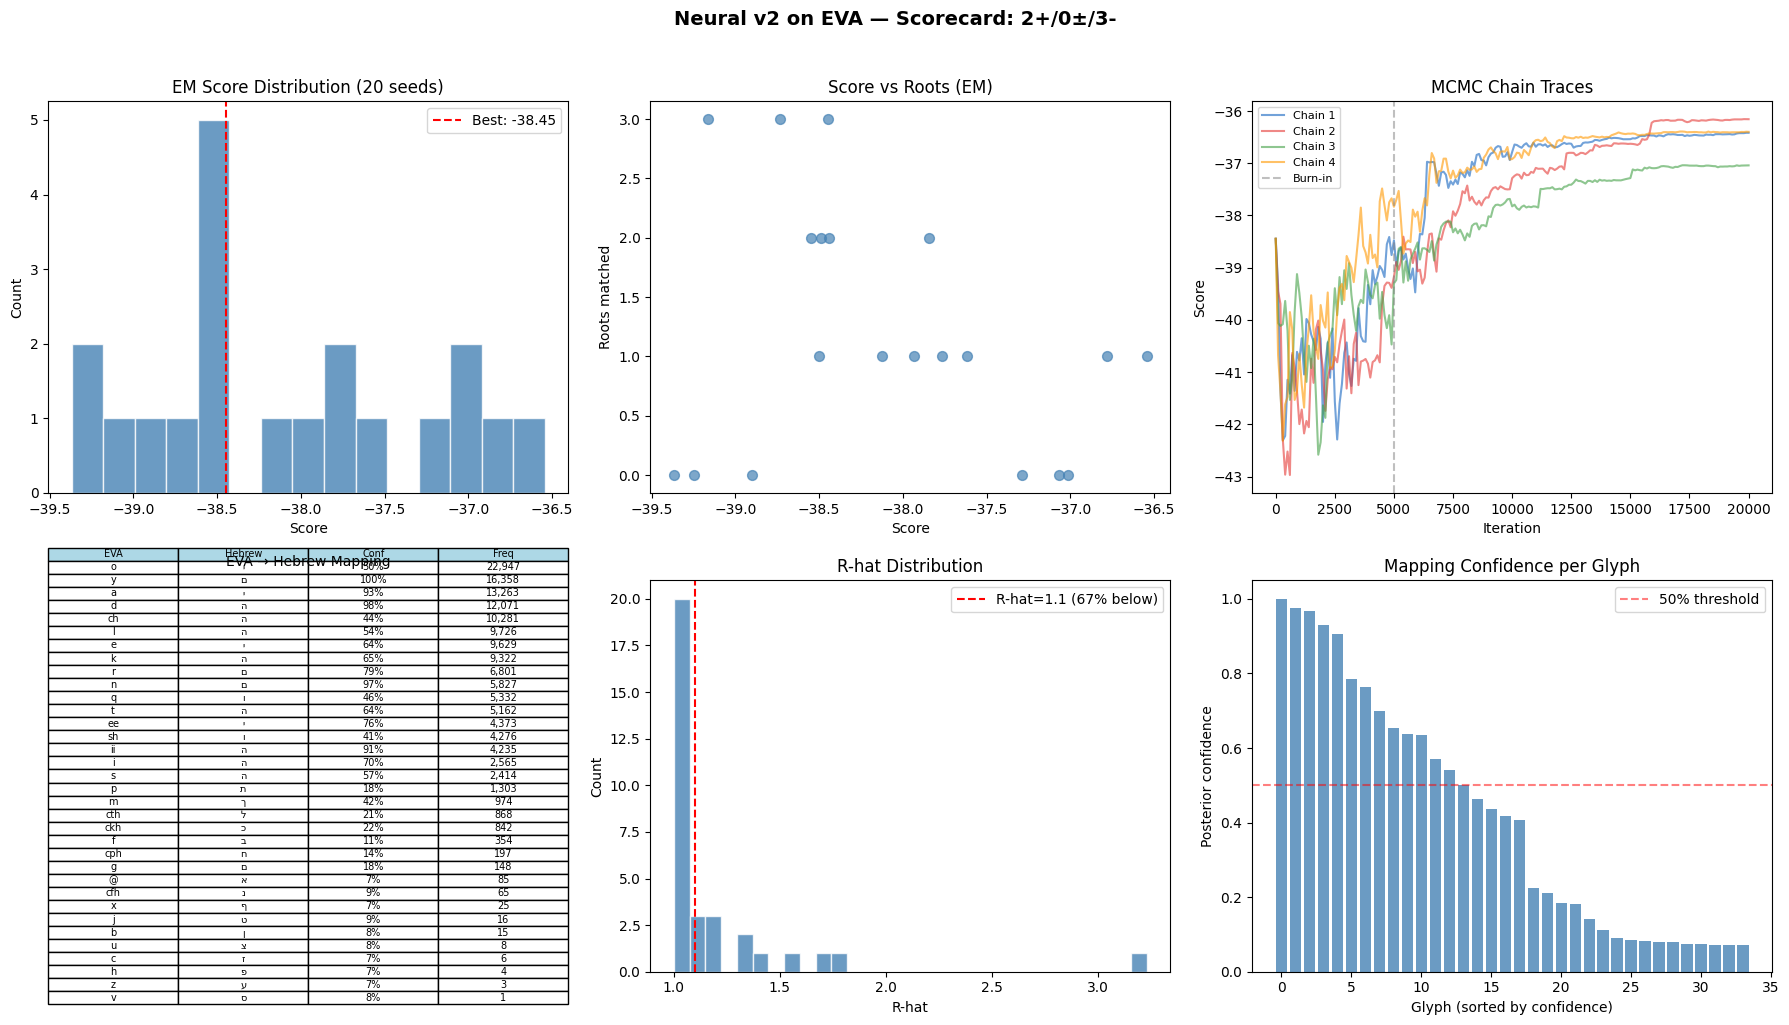

Saved: images/neural_v2_eva.png


In [11]:
# ── Cell 11: Visualizations ───────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. EM score distribution across seeds
ax = axes[0, 0]
scores_arr = [r['score'] for r in multi_seed_results]
ax.hist(scores_arr, bins=15, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(BEST['score'], color='red', ls='--', label=f'Best: {BEST["score"]:.2f}')
ax.set_xlabel('Score'); ax.set_ylabel('Count')
ax.set_title(f'EM Score Distribution ({N_SEEDS} seeds)')
ax.legend()

# 2. Score vs Roots scatter
ax = axes[0, 1]
roots_arr = [r['n_roots'] for r in multi_seed_results]
ax.scatter(scores_arr, roots_arr, c='steelblue', s=50, alpha=0.7)
ax.set_xlabel('Score'); ax.set_ylabel('Roots matched')
ax.set_title('Score vs Roots (EM)')

# 3. MCMC chain traces
ax = axes[0, 2]
colors_ch = ['#1565C0', '#E53935', '#43A047', '#FF9800']
for i, ch in enumerate(mcmc_chains):
    sc = ch['chain_scores']
    thin_sc = sc[::100]  # thin for plotting
    ax.plot(range(0, len(sc), 100), thin_sc, color=colors_ch[i],
            alpha=0.6, label=f'Chain {i+1}')
ax.axvline(BURN_IN, color='gray', ls='--', alpha=0.5, label='Burn-in')
ax.set_xlabel('Iteration'); ax.set_ylabel('Score')
ax.set_title('MCMC Chain Traces')
ax.legend(fontsize=8)

# 4. Mapping table (EVA glyph → Hebrew char)
ax = axes[1, 0]
ax.axis('off')
# Sort by frequency
glyph_freq = Counter(g for w in palabras for g in w)
sorted_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)
table_data = []
for g in sorted_glyphs:
    c = mapping_eva.get(g, '?')
    conf = conf_eva.get(g, 0)
    freq = glyph_freq[g]
    table_data.append([g, c, f'{conf:.0%}', f'{freq:,}'])
cols = ['EVA', 'Hebrew', 'Conf', 'Freq']
table = ax.table(cellText=table_data, colLabels=cols, loc='center',
                 cellLoc='center', colColours=['lightblue']*4)
table.auto_set_font_size(False)
table.set_fontsize(7)
table.scale(1, 0.7)
ax.set_title('EVA → Hebrew Mapping', fontsize=10, pad=10)

# 5. R-hat distribution
ax = axes[1, 1]
rhat_finite = [v for v in rhat_vals if v < 5]
ax.hist(rhat_finite, bins=30, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(1.1, color='red', ls='--', label=f'R-hat=1.1 ({pct_converged:.0f}% below)')
ax.set_xlabel('R-hat'); ax.set_ylabel('Count')
ax.set_title('R-hat Distribution')
ax.legend()

# 6. Posterior confidence distribution
ax = axes[1, 2]
confs = sorted(conf_eva.values(), reverse=True)
ax.bar(range(len(confs)), confs, color='steelblue', alpha=0.8)
ax.axhline(0.5, color='red', ls='--', alpha=0.5, label='50% threshold')
ax.set_xlabel('Glyph (sorted by confidence)')
ax.set_ylabel('Posterior confidence')
ax.set_title('Mapping Confidence per Glyph')
ax.legend()

plt.suptitle(f'Neural v2 on EVA — Scorecard: {n_pass}+/{n_marg}±/{n_fail}-',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('images/neural_v2_eva.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: images/neural_v2_eva.png')

In [ ]:
# ── Cell 12: Export results → neural_v2_eva_results.json ───────────

mapping_serializable = {g: c for g, c in mapping_eva.items()}

posterior_serializable = {}
for g, dist in posterior_eva.items():
    posterior_serializable[g] = {c: round(p, 4) for c, p in dist.items() if p > 0.01}

class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, np.ndarray): return obj.tolist()
        if isinstance(obj, set): return sorted(obj)
        return super().default(obj)

resultados = {
    'metadata': {
        'notebook': '24_neural_v2_eva.ipynb',
        'model': 'neural_lstm_eva_unconstrained',
        'language': 'hebrew',
        'transcription': 'EVA (ZL3b)',
        'description': 'Neural v2 pipeline on EVA transcription (34 types, unconstrained)',
    },
    'corpus': {
        'n_words': len(palabras),
        'n_glyphs': sum(len(w) for w in palabras),
        'n_types': len(VOCAB),
        'mean_word_len': round(float(np.mean([len(w) for w in palabras])), 2),
        'sigma_over_A': round(len(VOCAB) / len(target_chars), 2),
    },
    'neural_lm': {
        'architecture': 'LSTM 2-layer, embed=32, hidden=192, dropout=0.2',
        'n_params': sum(p.numel() for p in neural_lm.parameters()),
        'train_epochs': len(train_losses),
        'best_val_loss': round(float(best_val_loss), 4),
    },
    'multi_seed_results': [{
        'seed': r['seed'], 'score': round(float(r['score']), 4),
        'K_eff': int(r['K_eff']),
        'n_roots': int(r['n_roots']),
        'roots_list': sorted(r['roots']),
        'iter_converged': int(r['iter_converged']),
        'elapsed': round(float(r['elapsed']), 1),
    } for r in multi_seed_results],
    'best_candidate': {
        'seed': int(BEST['seed']),
        'score': round(float(BEST['score']), 4),
        'K_eff': int(BEST['K_eff']),
        'n_roots': int(BEST['n_roots']),
    },
    'mcmc_results': {
        'n_chains': N_CHAINS,
        'n_iter': N_ITER,
        'burn_in': BURN_IN,
        'best_score': round(float(global_best_score), 4),
        'K_eff': int(K_used),
        'pct_converged_rhat': round(float(pct_converged), 1),
        'chain_accept_rates': [round(float(ch['accept_rate']), 3) for ch in mcmc_chains],
    },
    'validation_scorecard': {s['Test']: s['Verdict'] for s in scorecard},
    'validation_details': {
        'collapse_mean_z': round(float(mean_z), 3),
        'ngram_percentile': round(float(pct_ngram), 1),
        'ngram_jsd': round(float(real_jsd), 4),
        'roots_matched': int(len(roots_matched)),
        'roots_list': sorted(roots_matched),
        'enrichment': round(float(enrichment), 1),
        'cardinality_ratio': round(float(K_ratio), 3),
        'word_length_z': round(float(z_len), 2),
    },
    'scorecard_summary': f'{n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL',
    'mapping': mapping_serializable,
    'posterior_top': posterior_serializable,
    'rhat': {g: round(float(v), 4) for g, v in rhat_eva.items()
             if isinstance(v, (int, float, np.floating)) and not np.isnan(v)},
    'multi_seed_summary': {
        'n_seeds': N_SEEDS,
        'score_mean': round(float(np.mean([r['score'] for r in multi_seed_results])), 4),
        'score_std': round(float(np.std([r['score'] for r in multi_seed_results])), 4),
        'roots_mean': round(float(np.mean([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_std': round(float(np.std([r['n_roots'] for r in multi_seed_results])), 1),
        'roots_max': int(max(r['n_roots'] for r in multi_seed_results)),
    },
}

with open('neural_v2_eva_resultados.json', 'w') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, cls=NumpyEncoder)
print('Results saved to neural_v2_eva_results.json')

print(f'\n── Summary ──')
print(f'Transcription: EVA ({len(VOCAB)} types, |Σ|/|A|={len(VOCAB)/len(target_chars):.2f})')
print(f'N-gram percentile: {pct_ngram:.1f}%')
print(f'Roots: {len(roots_matched)} {sorted(roots_matched)}')
print(f'R-hat convergence: {pct_converged:.0f}%')
print(f'Scorecard: {n_pass} PASS / {n_marg} MARGINAL / {n_fail} FAIL')

Results saved to neural_v2_eva_resultados.json

── Summary ──
Transcription: EVA (34 types, |Σ|/|A|=1.26)
N-gram percentile: 0.0%
Roots: 0 []
R-hat convergence: 67%
Scorecard: 2 PASS / 0 MARGINAL / 3 FAIL


: 